In [3]:
import os, random, shutil
from glob import glob
import torch
import torch.nn.functional as F
from torch import nn, optim, Tensor
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
import timm 
import pandas as pd

In [4]:
# reproducibility
random.seed(42)
torch.manual_seed(42)


In [5]:
# 1) Stratified sampling + split
def stratified_sample_split(raw_dir, out_base, total,
                            splits=('train','val','test'),
                            ratios=(0.8,0.1,0.1)):
    classes = [d for d in os.listdir(raw_dir) if os.path.isdir(os.path.join(raw_dir,d))]
    per_cls = total // len(classes)
    for cls in classes:
        imgs = glob(os.path.join(raw_dir,cls,'*'))
        sel  = imgs if len(imgs)<=per_cls else random.sample(imgs,per_cls)
        random.shuffle(sel)
        n     = len(sel)
        i1    = int(ratios[0]*n)
        i2    = i1 + int(ratios[1]*n)
        groups = {
            'train': sel[:i1],
            'val':   sel[i1:i2],
            'test':  sel[i2:]
        }
        for split, files in groups.items():
            d = os.path.join(out_base, split, cls)
            os.makedirs(d, exist_ok=True)
            for f in files:
                shutil.copy(f, d)


In [6]:
# Dataset roots — set env vars or place datasets under ./data/
# CONTENT_DIR: 'image-classification' Kaggle dataset (images/images)
# STYLE_DIR:   'wikiart' Kaggle dataset
RAW_CONTENT = os.environ.get('CONTENT_DIR', 'data/image-classification/images/images')
RAW_STYLE   = os.environ.get('STYLE_DIR',   'data/wikiart')
WORK_BASE   = os.environ.get('WORK_DIR',    'outputs')
DATA_BASE   = os.path.join(WORK_BASE, 'data')

In [7]:
# sample 7k content, 3k style
stratified_sample_split(RAW_CONTENT, os.path.join(DATA_BASE,'content'), total=7000)
stratified_sample_split(RAW_STYLE,   os.path.join(DATA_BASE,'style'),   total=3000)

print('Data directories created under', DATA_BASE)

Data directories created under /kaggle/working/data


In [8]:
# 2) Print counts
print("Counts per split:")
for kind in ('content','style'):
    for split in ('train','val','test'):
        path = os.path.join(DATA_BASE, kind, split)
        cnt = sum(len(f) for _,_,f in os.walk(path))
        print(f"  {kind:7s} {split:5s}: {cnt}")


Counts per split:
  content train: 5600
  content val  : 700
  content test : 700
  style   train: 2366
  style   val  : 295
  style   test : 322


In [9]:
# 3) Transforms & Dataset
tf = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

In [10]:
class StyleDS(Dataset):
    def __init__(self, root, split): 
        self.C = glob(os.path.join(root,'content',split,'*','*'))
        self.S = glob(os.path.join(root,'style',  split,'*','*'))
    def __len__(self):
        return min(len(self.C), len(self.S))
    def __getitem__(self,i):
        c = Image.open(self.C[i]).convert('RGB')
        s = Image.open(self.S[i % len(self.S)]).convert('RGB')
        return tf(c), tf(s), torch.rand(1)


In [11]:
train_dl = DataLoader(StyleDS(DATA_BASE,'train'), batch_size=8, shuffle=True)
val_dl   = DataLoader(StyleDS(DATA_BASE,'val'),   batch_size=8)
test_dl  = DataLoader(StyleDS(DATA_BASE,'test'),  batch_size=4)


In [12]:
def adain(content_feat: Tensor, style_feat: Tensor, eps: float = 1e-5) -> Tensor:
    c_mean = content_feat.mean(dim=[2,3], keepdim=True)
    c_std  = content_feat.std(dim=[2,3], keepdim=True)
    s_mean = style_feat.mean(dim=[2,3], keepdim=True)
    s_std  = style_feat.std(dim=[2,3], keepdim=True)
    normalized = (content_feat - c_mean) / (c_std + eps)
    return normalized * s_std + s_mean

In [13]:
class StyleNet(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = models.vgg19(pretrained=True).features
        self.enc = nn.Sequential(*list(vgg)[:21])
        for p in self.enc.parameters():
            p.requires_grad=False
        self.dec = nn.Sequential(
            nn.Conv2d(512,256,3,1,1), nn.ReLU(), nn.Upsample(scale_factor=2),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,128,3,1,1), nn.ReLU(), nn.Upsample(scale_factor=2),
            nn.Conv2d(128,64,3,1,1),  nn.ReLU(), nn.Upsample(scale_factor=2),
            nn.Conv2d(64,3,3,1,1)
        )
    def forward(self,c,s,t):
        cf = self.enc(c)
        sf = self.enc(s)
        tf_ = adain(cf, sf)
        feat = t.view(-1,1,1,1)*tf_ + (1-t).view(-1,1,1,1)*cf
        return self.dec(feat)


In [14]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = StyleNet().to(device)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth
100%|██████████| 548M/548M [00:02<00:00, 233MB/s]


In [15]:
mse      = nn.MSELoss()
opt      = optim.Adam(model.dec.parameters(), lr=1e-4)
vgg_loss = models.vgg19(pretrained=True).features[:21].to(device).eval()


In [16]:
def gram(x: Tensor) -> Tensor:
    b,c,h,w = x.size()
    f = x.view(b,c,h*w)
    return torch.bmm(f, f.transpose(1,2))

In [17]:
def loss_fn(o: Tensor, c: Tensor, s: Tensor) -> Tensor:
    o = F.interpolate(o, size=(256,256), mode='bilinear', align_corners=False)
    c = F.interpolate(c, size=(256,256), mode='bilinear', align_corners=False)
    s = F.interpolate(s, size=(256,256), mode='bilinear', align_corners=False)
    of = vgg_loss(o)
    cf = vgg_loss(c)
    sf = vgg_loss(s)
    return mse(of, cf) + mse(gram(of), gram(sf))


In [18]:
best_val, patience, counter = float('inf'), 5, 0
num_epochs = 20
for ep in range(1, num_epochs+1):
    model.train()
    tloss = 0.0
    for c,s,t in train_dl:
        c,s,t = c.to(device), s.to(device), t.to(device)
        opt.zero_grad()
        out = model(c,s,t)
        l   = loss_fn(out, c, s)
        l.backward()
        opt.step()
        tloss += l.item()
    tloss /= len(train_dl)

    model.eval()
    vloss = 0.0
    with torch.no_grad():
        for c,s,_ in val_dl:
            c,s = c.to(device), s.to(device)
            t_t  = torch.rand(c.size(0),1).to(device)
            vloss += loss_fn(model(c,s,t_t), c, s).item()
    vloss /= len(val_dl)

    print(f"Epoch {ep:02d} train {tloss:.4f} val {vloss:.4f}")
    if vloss < best_val:
        best_val, counter = vloss, 0
    else:
        counter += 1
        if counter >= patience:
            print(f"Early stopping at epoch {ep}")
            break


/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1045: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01 train 13096013.2162 val 13464906.6284
Epoch 02 train 11450259.8429 val 12109676.5811
Epoch 03 train 10690970.1014 val 12069141.9797
Epoch 04 train 10269280.5498 val 11507529.7432
Epoch 05 train 9962460.2517 val 10857430.5676
Epoch 06 train 9804615.2221 val 11585619.4932
Epoch 07 train 9427797.2052 val 11372987.2297
Epoch 08 train 9491762.6022 val 10931243.0473
Epoch 09 train 9823121.6575 val 11787630.9595
Epoch 10 train 9283176.7280 val 11627204.7365
Early stopping at epoch 10


In [19]:
# 6) Hyperparameter sweep over t on train/val/test splits
def compute_losses(output, content, style):
    of = vgg_loss(F.interpolate(output, size=(256,256), mode='bilinear', align_corners=False))
    cf = vgg_loss(F.interpolate(content, size=(256,256), mode='bilinear', align_corners=False))
    sf = vgg_loss(F.interpolate(style,    size=(256,256), mode='bilinear', align_corners=False))
    cl = mse(of, cf).item()
    sl = mse(gram(of), gram(sf)).item()
    return cl, sl

In [20]:
results = []
for split_name, dl in [('train', train_dl), ('val', val_dl), ('test', test_dl)]:
    with torch.no_grad():
        for t_val in [i/10 for i in range(11)]:
            sum_cl, sum_sl, n = 0.0, 0.0, 0
            for c,s,_ in dl:
                c,s = c.to(device), s.to(device)
                t_tensor = torch.full((c.size(0),1), t_val, device=device)
                out = model(c,s,t_tensor)
                cl, sl = compute_losses(out, c, s)
                sum_cl += cl
                sum_sl += sl
                n     += 1
            results.append({
                'split': split_name,
                't':          t_val,
                'content_loss': sum_cl / n,
                'style_loss':   sum_sl / n,
                'total_loss':  (sum_cl + sum_sl) / n
            })

In [21]:
df = pd.DataFrame(results)
print(df)
best = df[df.split=='val'].sort_values('total_loss').iloc[0]
print(f"Best t on val: {best.t:.1f} (loss {best.total_loss:.4f})")


    split    t  content_loss    style_loss    total_loss
0   train  0.0     26.275304  1.230218e+07  1.230220e+07
1   train  0.1     26.181318  1.119187e+07  1.119189e+07
2   train  0.2     26.140618  1.023108e+07  1.023111e+07
3   train  0.3     26.132501  9.451064e+06  9.451090e+06
4   train  0.4     26.172435  8.847302e+06  8.847328e+06
5   train  0.5     26.250210  8.397205e+06  8.397231e+06
6   train  0.6     26.376358  8.104291e+06  8.104317e+06
7   train  0.7     26.532624  7.957009e+06  7.957035e+06
8   train  0.8     26.736015  7.952699e+06  7.952726e+06
9   train  0.9     26.986329  8.104372e+06  8.104399e+06
10  train  1.0     27.264005  8.393215e+06  8.393242e+06
11    val  0.0     26.405137  1.491441e+07  1.491444e+07
12    val  0.1     26.307872  1.377033e+07  1.377036e+07
13    val  0.2     26.258524  1.270703e+07  1.270706e+07
14    val  0.3     26.255354  1.177876e+07  1.177879e+07
15    val  0.4     26.300364  1.099824e+07  1.099826e+07
16    val  0.5     26.395281  1

In [22]:
# 7) Save model weights and traced
torch.save(model.state_dict(), 'style_transfer_weights.pth')
example_c = torch.randn(1,3,256,256, device=device)
example_s = torch.randn(1,3,256,256, device=device)
example_t = torch.full((1,1), best.t, device=device)
traced = torch.jit.trace(model, (example_c, example_s, example_t))
traced.save('style_transfer_traced.pt')


In [23]:
# 8) Test inference + collect examples
allC, allS, allO = [],[],[]
model.eval()
with torch.no_grad():
    for c,s,_ in test_dl:
        c,s = c.to(device), s.to(device)
        t_tensor = torch.full((c.size(0),1), best.t, device=device)
        out = model(c,s,t_tensor)
        for i in range(c.size(0)):
            allC.append(c[i].cpu())
            allS.append(s[i].cpu())
            allO.append(out[i].cpu())
print(f"Collected {len(allC)} samples")

Collected 322 samples


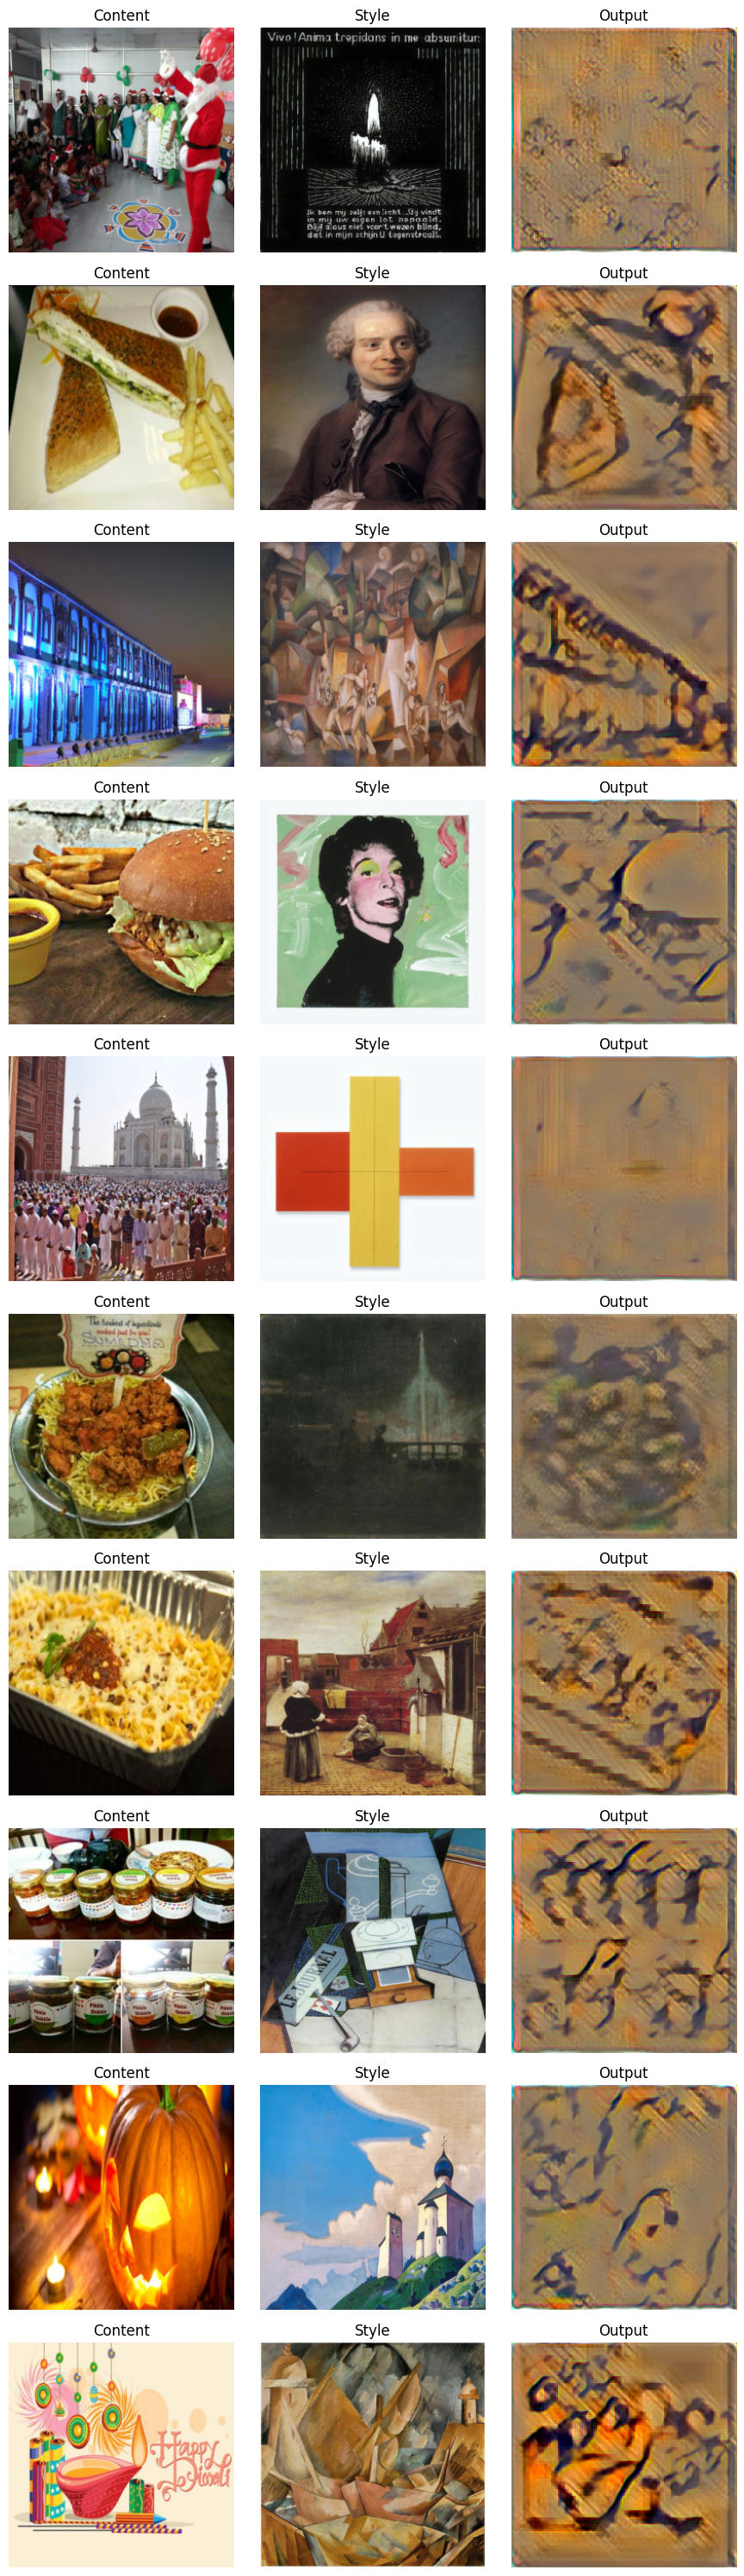

In [24]:
# 9) Plot random examples
def to_img(x):
    mean = torch.tensor([0.485,0.456,0.406]).view(3,1,1)
    std  = torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    im = x * std + mean
    return im.clamp(0,1).permute(1,2,0).numpy()

import random
idxs = random.sample(range(len(allC)), 10)
fig, ax = plt.subplots(10,3,figsize=(9,30))
for row,i in enumerate(idxs):
    ax[row,0].imshow(to_img(allC[i])); ax[row,0].set_title("Content"); ax[row,0].axis('off')
    ax[row,1].imshow(to_img(allS[i])); ax[row,1].set_title("Style");   ax[row,1].axis('off')
    ax[row,2].imshow(to_img(allO[i])); ax[row,2].set_title("Output");  ax[row,2].axis('off')
plt.tight_layout()
plt.show()